In [1]:
## Libraries 

import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import binom

<div>
<h2>Contents</h2>
<ol>
    <li>Ring Lattice</li>
    <li>Random Networks</li>
    <li>Small World Networks</li>
    <li>Scale-Free Networks</li>
</ol>
</div>

<div> <h2 style = "text-align:center;"> FUNCTIONS </h2> </div>

In [2]:
import networkx as nx

def calculate_distance_metrics(G, mode="giant"):
    """Calculates diameter and average shortest path length for connected or

    unconnected graphs.

    Parameters:
    -----------
    G : nx.Graph
        The input NetworkX graph.
    mode : str, optional (default='giant')
        - 'giant': Evaluates metrics strictly on the largest connected component.
        - 'all': Computes the maximum diameter across all components, and the
                 pair-weighted average path length over all reachable pairs.

    Returns:
    --------
    diameter : int or float
        Diameter of the network/component. Returns 0 if no edges exist.
    avg_path_length : float
        Average shortest path length. Returns 0.0 if no edges exist.
    """
    # Case 1: Fully connected graph
    if nx.is_connected(G):
        if len(G) <= 1:
            return 0, 0.0
        return nx.diameter(G), nx.average_shortest_path_length(G)

    # Filter connected components that have at least 2 nodes
    components = [
        G.subgraph(c).copy() for c in nx.connected_components(G) if len(c) > 1
    ]

    # Handle edge case: no edges exist in the graph (all isolated nodes)
    if not components:
        return 0, 0.0

    # Case 2: Unconnected - Giant Component Mode (Standard)
    if mode == "giant":
        giant = max(components, key=len)
        return nx.diameter(giant), nx.average_shortest_path_length(giant)

    # Case 3: Unconnected - Aggregate Across All Components Mode
    elif mode == "all":
        # Global diameter is the maximum diameter found in any component
        diam = max(nx.diameter(c) for c in components)

        # Weighted average shortest path length over all connected pairs
        total_reachable_pairs = 0
        weighted_path_sum = 0.0

        for c in components:
            n_c = len(c)
            pairs_c = n_c * (n_c - 1) / 2
            l_c = nx.average_shortest_path_length(c)

            weighted_path_sum += l_c * pairs_c
            total_reachable_pairs += pairs_c

        avg_path = (
            (weighted_path_sum / total_reachable_pairs)
            if total_reachable_pairs > 0
            else 0.0
        )
        return diam, avg_path

    else:
        raise ValueError("Mode must be either 'giant' or 'all'.")

<div style="text-align: center; font-size:24px ">Ring Lattice</div>
<div>Ring lattice (RL) belongs to the family of regular network meaning that all nodes have constant degree, $deg(n_{i}) = k$ for all $i$, called $k$-regular network. Apart from the regular network, in a ring lattice network, all nodes are connected to $\frac{k}{2}$ neighbours on both side. A ring lattice is a kind of regular graph, which Watts and Strogatz use as the basis of their model (with probability of wiring, $p=0$). </div>


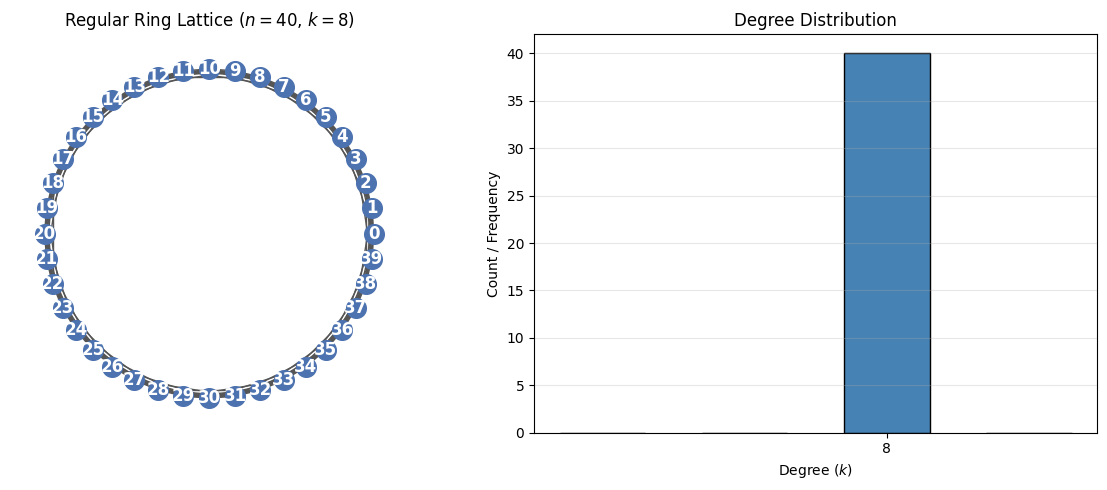

In [3]:
n_RL = 40
k_RL = 8

# Generate regular ring lattice (p = 0 ensures no rewired edges)
ring_lattice = nx.watts_strogatz_graph(n=n_RL, k=k_RL, p=0)
degrees_RL = [d for n_RL, d in ring_lattice.degree()]


# Create side-by-side axes (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 1. Left plot: Ring lattice visualization
pos = nx.circular_layout(ring_lattice)
nx.draw(
    ring_lattice,
    pos,
    ax=ax1,  # Target the left axis
    with_labels=True,
    node_color="#4C72B0",
    node_size=200,
    font_color="white",
    font_weight="bold",
    edge_color="#555555",
)
ax1.set_title(f"Regular Ring Lattice ($n={n_RL}$, $k={k_RL}$)")
ax1.set_aspect("equal")  # Keeps the circular layout round

# 2. Right plot: Degree distribution histogram
ax2.hist(
    degrees_RL,
    bins=range(min(degrees_RL) - 2, max(degrees_RL) + 3),
    align="left",
    rwidth=0.6,
    color="steelblue",
    edgecolor="black",
)
ax2.set_title("Degree Distribution")
ax2.set_xlabel("Degree ($k$)")
ax2.set_ylabel("Count / Frequency")
ax2.set_xticks(range(min(degrees_RL), max(degrees_RL) + 1))
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



In [4]:

r_RL, l_RL = calculate_distance_metrics(ring_lattice, mode="all") # shortest path is for all components and averaging them if graph is unconnected.
print('Diameter of the network:', r_RL)
print('The average shortest path: ', round(l_RL,2))

# Clustering Coefficients
# Overall average clustering coefficient of the network
avg_clustering_RL = nx.average_clustering(ring_lattice)
print("Average clustering through nodes: ", avg_clustering_RL)
# Global clustering coefficient (transitivity: ratio of 3x triangles to triads)
transitivity_RL = nx.transitivity(ring_lattice)
print("Transitivity: ", transitivity_RL)

Diameter of the network: 5
The average shortest path:  2.95
Average clustering through nodes:  0.6428571428571429
Transitivity:  0.6428571428571429


In [5]:
summary_records = []
# --- 1. Ring Lattice ---
summary_records.append(
    {
        "Topology": "Regular Ring Lattice",
        "Parameters": f"n={n_RL}, k={k_RL}",
        "Nodes (N)": n_RL,
        "Edges (M)": ring_lattice.number_of_edges(),
        "Avg Degree ⟨k⟩": 4.0,
        "Diameter (D)": r_RL,
        "Avg Path Length ⟨L⟩": round(l_RL, 3),
        "Clustering Coeff (C)": round(avg_clustering_RL, 3),
        "Transitivity": round(transitivity_RL, 3),
        "Theoretical Distribution": f"$p(k) = k$",      
    }
)

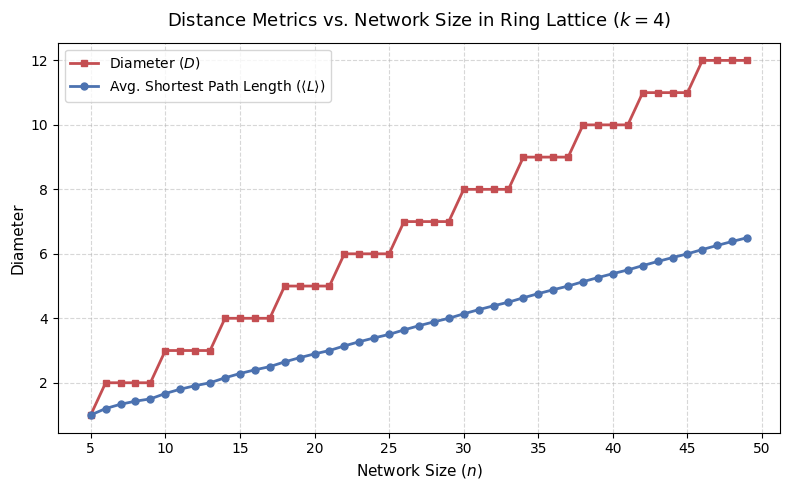

In [6]:
k = 4  # Each node connects to k nearest neighbors (must be even)
n_size = 50
n_values = range(k+1, n_size)
avg_path_lengths = []
diameters = []
for n in n_values:
    G_RL = nx.watts_strogatz_graph(n=n, k=k, p=0) 
    # l = nx.average_shortest_path_length(G)
    # r = nx.diameter(G)
    r, l = calculate_distance_metrics(G_RL)
    avg_path_lengths.append(l)
    diameters.append(r)

plt.figure(figsize=(8, 5))

# Plot Diameter
plt.plot(
    list(n_values),
    diameters,
    marker="s",
    markersize=5,
    linestyle="-",
    linewidth=2,
    color="#C44E52",
    label=r"Diameter ($D$)",
)

# Plot Average Shortest Path Length
plt.plot(
    list(n_values),
    avg_path_lengths,
    marker="o",
    markersize=5,
    linestyle="-",
    linewidth=2,
    color="#4C72B0",
    label=r"Avg. Shortest Path Length ($\langle L \rangle$)",
)

plt.title(
    f"Distance Metrics vs. Network Size in Ring Lattice ($k={k}$)",
    fontsize=13,
    pad=12,
)
plt.xlabel("Network Size ($n$)", fontsize=11)
plt.ylabel("Diameter", fontsize=11)
plt.xticks(range(k+1, n_size+1, 5))
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, fontsize=10)

plt.tight_layout()
plt.show()



<div style="text-align: center; font-size:24px ">Random Networks</div>
<div> Random networks, which have been introduced by Paul Erdös and Alfred Rényi in the early 1960s, have the same probability to draw a link between any two nodes. For a network with $N$ nodes and $n$ links, the possible number of networks can be constructed is $n$ choose number of all links, $\frac{N(N−1)}{2}$. The degree $k$ of any node is governed by a binomial distribution:
\[ 
    P(k)=\binom{N-1}{k}p^{k}(1-p)^{N-1-k}
\]
</div>

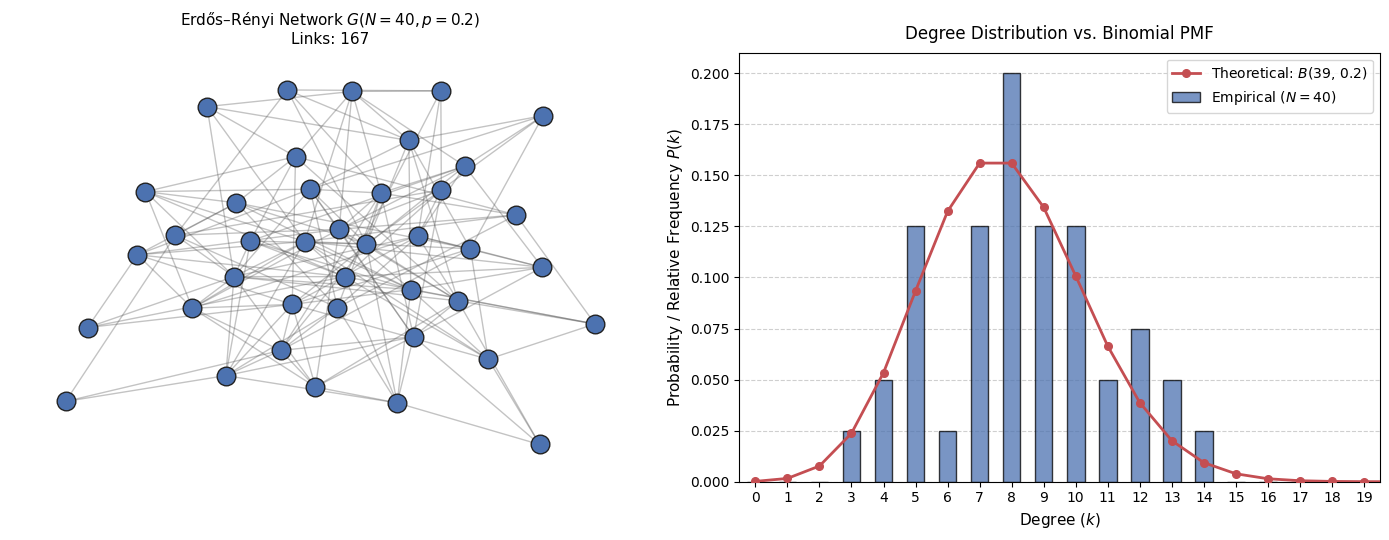

In [7]:
# 1. Network & Distribution Parameters
n_ER = 40  # Number of nodes
n_trials = n_ER - 1  # 39 possible connections per node
p = 0.2  # Edge probability

# 2. Generate Erdős–Rényi G(N, p) Graph
G_ER = nx.erdos_renyi_graph(n=n_ER, p=p) #, seed=42)

# 3. Calculate Degree Metrics & Binomial PMF
degrees_ER = [deg for _, deg in G_ER.degree()]
k_values = np.arange(0, n_trials + 1)

# Empirical relative frequencies
deg_counts_ER = {k: 0 for k in k_values}
for d in degrees_ER:
    deg_counts_ER[d] += 1
empirical_probs = [deg_counts_ER[k] / n_ER for k in k_values]

# Theoretical binomial probabilities: B(N-1, p)
theoretical_probs = binom.pmf(k_values, n_trials, p)

# Determine visible x-range for the distribution plot
active_k = k_values[(theoretical_probs > 1e-4) | (np.array(empirical_probs) > 0)]
x_min = max(0, active_k.min() - 1)
x_max = min(n_trials, active_k.max() + 1)

# 4. Side-by-Side Figure Setup
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Left Plot: Network Graph Visualization ---
pos = nx.spring_layout(G_ER, seed=42)
nx.draw_networkx_nodes(
    G_ER, pos, ax=ax1, node_size=180, node_color="#4C72B0", edgecolors="#222222"
)
nx.draw_networkx_edges(G_ER, pos, ax=ax1, alpha=0.35, edge_color="#555555")
num_edges_ER = int(sum(degrees_ER) / 2)
ax1.set_title(
    f"Erdős–Rényi Network $G(N={n_ER}, p={p})$\nLinks: {num_edges_ER}", fontsize=11
)
ax1.axis("off")

# --- Right Plot: Degree Distribution & Binomial Fit ---
ax2.bar(
    k_values,
    empirical_probs,
    width=0.55,
    color="#4C72B0",
    alpha=0.75,
    edgecolor="black",
    label=f"Empirical ($N={n_ER}$)",
    zorder=2,
)
ax2.plot(
    k_values,
    theoretical_probs,
    "o-",
    color="#C44E52",
    linewidth=2,
    markersize=5.5,
    label=rf"Theoretical: $B({n_trials},\, {p})$",
    zorder=3,
)

ax2.set_title("Degree Distribution vs. Binomial PMF", fontsize=12, pad=10)
ax2.set_xlabel("Degree ($k$)", fontsize=11)
ax2.set_ylabel("Probability / Relative Frequency $P(k)$", fontsize=11)
ax2.set_xlim(x_min - 0.5, x_max + 0.5)
ax2.set_xticks(np.arange(x_min, x_max + 1))
ax2.grid(axis="y", linestyle="--", alpha=0.6, zorder=1)
ax2.legend(frameon=True, fontsize=10)

plt.tight_layout()
plt.show()

In [8]:
r_ER, l_ER = calculate_distance_metrics(G_ER, mode="giant") # if graph is unconnected, it chooses the biggest components and calculates the average of shortest pathes through components. 
print('Diameter of the network:', r_ER)
print('The average shortest path: ', round(l_ER,2))
# Clustering Coefficients
# Overall average clustering coefficient of the network
avg_clustering_ER = nx.average_clustering(G_ER)
print("Average clustering through nodes: ", avg_clustering_ER)
# Global clustering coefficient (transitivity: ratio of 3x triangles to triads)
transitivity_ER = nx.transitivity(G_ER)
print("Transitivity: ", transitivity_ER)

summary_records.append(
    {
        "Topology": "Erdos-Renyi Random Network",
        "Parameters": f"n={n_ER}, p={p}",
        "Nodes (N)": n_RL,
        "Edges (M)": G_ER.number_of_edges(),
        "Avg Degree ⟨k⟩": sum(degrees_ER)/n_ER,
        "Diameter (D)": r_ER,
        "Avg Path Length ⟨L⟩": round(l_ER, 3),
        "Clustering Coeff (C)": round(avg_clustering_ER, 3),
        "Transitivity": round(transitivity_ER, 3),
        "Theoretical Distribution": f"$p(k) \sim binom(n-1,p)$"
    }
)

Diameter of the network: 4
The average shortest path:  1.92
Average clustering through nodes:  0.21918831168831168
Transitivity:  0.20160701241782322


<div style="text-align: center; font-size:24px">Small World Network</div>
<div style = "text-align: justify;">
As we see in the ring lattice, the shortest path length depends on the network size, and it increases as N rises. However, in most of the real networks, despite their often large size, they have a relatively short path length in average between any two nodes. This property is first investigated in a social science network inferred from Milgram’s experiment. In his experiment, randomly selected individuals in Nebraska were asked to forward a letter to a distant target individual if they knew them, based on provided information such as names, occupation, and approximate location. If they did not know the target, they were instructed to send the letter to someone who might know the person. Milgram then tracked the path of the letters and surprisingly found that, on average, the letters reached the target individual
after only 6 deliveries. It shows that a network might have relatively small mean of the shortest path lengths even if it involves many nodes. This is known as small-wordness of a network, and it helps one to characterise the network at hand. Brain networks and World Wide Webs (WWW) are frequently classified as small world network because some links connects different clusters within these systems, significantly speeding up information transmission. <strong> Watts and Strogatz</strong> conducted research that showed similarities in the neural networks of Caenorhabditis elegans, the power grid of the western US, and the collaboration network of film actors.  They developed an algorithm to generate small-world (SW) a network which has 2 parameters, number of neighbours and probability of being connected. This algorithm starts with an initial network in which all nodes connected to a given number of nearest neighbours, and the links are reconstructed based on the given probability. Since some nodes will connect to a distant node, this increase the connectivity of network and eventually provide the property of small-wordness.
</div>

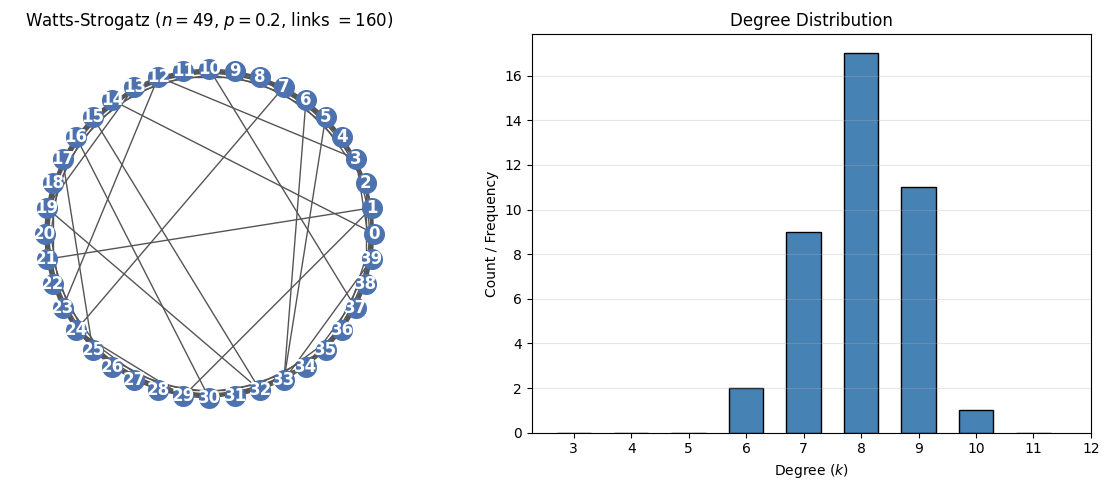

In [9]:

n_WS = 40 # number of nodes
k_WS = 8 # initially every node connected k-neighbours each side 
p_WS =0.1 # probability of re-wiring

G_WS = nx.watts_strogatz_graph(n_WS, k_WS, p_WS)
degrees_WS = [d for n, d in G_WS.degree()]


# Create side-by-side axes (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# 1. Left plot: Ring Watts-Strogatz visualization
pos = nx.circular_layout(G_WS)
nx.draw(
    G_WS,
    pos,
    ax=ax1,  # Target the left axis
    with_labels=True,
    node_color="#4C72B0",
    node_size=200,
    font_color="white",
    font_weight="bold",
    edge_color="#555555",
)
ax1.set_title(f"Watts-Strogatz ($n={n}$, $p={p}$, links $= {int(sum(degrees_WS)/2)}$)")
ax1.set_aspect("equal")  # Keeps the circular layout round

# 2. Right plot: Degree distribution histogram
ax2.hist(
    degrees_WS,
    bins=range(min(degrees_WS) - 3, max(degrees_WS) + 3),
    align="left",
    rwidth=0.6,
    color="steelblue",
    edgecolor="black",
)
ax2.set_title("Degree Distribution")
ax2.set_xlabel("Degree ($k$)")
ax2.set_ylabel("Count / Frequency")
ax2.set_xticks(range(min(degrees_WS)-3, max(degrees_WS)+3))
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [10]:
r_WS, l_WS = calculate_distance_metrics(G_WS, mode="all") # shortest path is for all components and averaging them if graph is unconnected.
print('Diameter of the network:', r_WS)
print('The average shortest path: ', round(l_WS,2))

# 3. Clustering Coefficients
# Overall average clustering coefficient of the network
avg_clustering_WS = nx.average_clustering(G_WS)
print("Average clustering through nodes: ", avg_clustering_WS)
# Global clustering coefficient (transitivity: ratio of 3x triangles to triads)
transitivity_WS = nx.transitivity(G_WS)
print("Transitivity: ", transitivity_WS)
# Node-by-node clustering coefficients

local_clustering_WS = nx.clustering(G_WS)
# print('local clustering: ', local_clustering)

summary_records.append(
    {
        "Topology": "Watts-Strogatz Small World Network",
        "Parameters": f"n={n_WS}, k={k_WS}, p={p_WS}",
        "Nodes (N)": n_WS,
        "Edges (M)": G_WS.number_of_edges(),
        "Avg Degree ⟨k⟩": sum(degrees_WS)/n_WS,
        "Diameter (D)": r_WS,
        "Avg Path Length ⟨L⟩": round(l_WS, 3),
        "Clustering Coeff (C)": round(avg_clustering_WS, 3),
        "Transitivity": round(transitivity_WS, 3),
        "Theoretical Distribution": f"-",      
    }
)


Diameter of the network: 4
The average shortest path:  2.21
Average clustering through nodes:  0.5020833333333333
Transitivity:  0.49119718309859156


<div style="text-align: center; font-size:24px">Scale-Free Network</div>
<div style = "text-align: justify;">
Traditionally, ER model has been extensively used to study in complex networks, assuming an equal connection probability for all nodes. However, the analyses of large real networks show that the degree distribution of most of them follows power-law instead of binomial distribution (or Poison distribution for large networks). Albert Laszlo Barabasi and Reka Albert analysed the topological structure of real-world networks like the WWW and the citation network of scientific articles, and they showed that the nodes with higher degrees tend to have a higher connection probability, which is called <b>“preferential attachment”</b>. Based on this observations, they devise an algorithm to generate scale-free (SF) network, is known as BA model. There are two generic mechanism underlying the algorithm: 
<ol>
    <li> New nodes get involved in the network in each iteration.</li>
    <li> The probability of being connected for the nodes depends on their existing number of connections. In such networks, the probability of nodes being rewired follows a distribution with a power-law decay, denoted as $p(k)\sim k^{-\gamma}$. </li></ol>
</div>

<div style="text-align: center; font-size:24px"> Prefential Attachment $\implies$ Rich gets rich, poor stays poor </div>


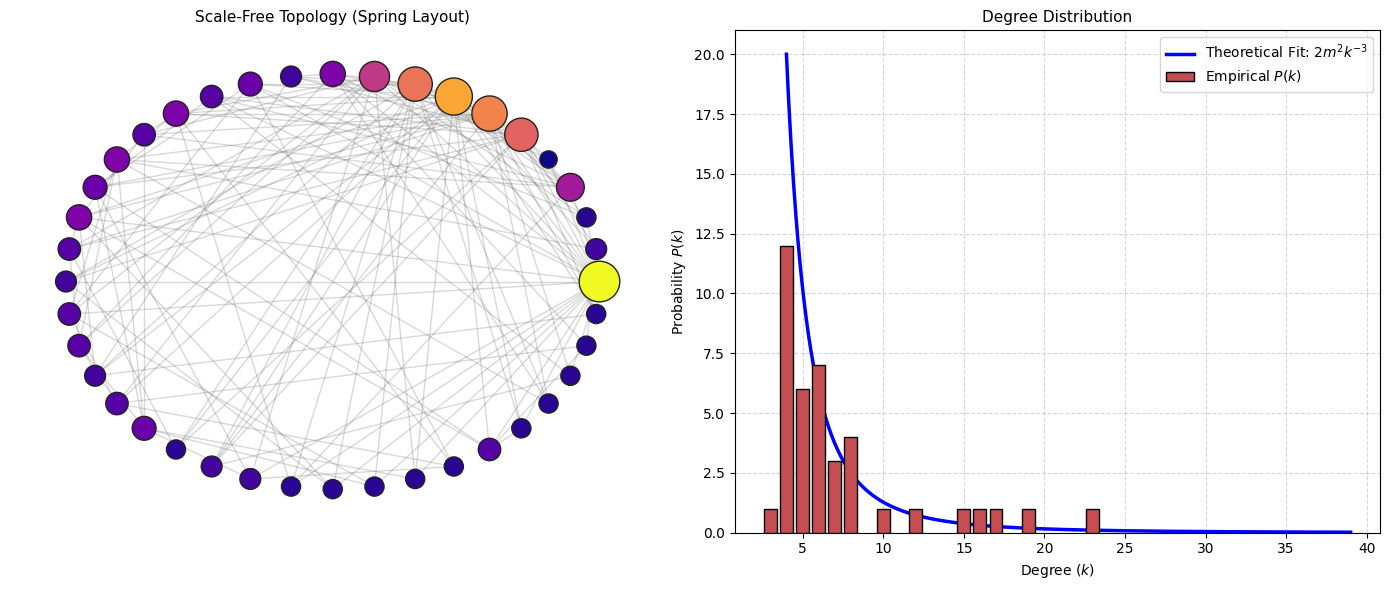

In [11]:
# 1. Generate a Scale-Free Network using Barabási–Albert (BA) model
# n: total number of nodes, m: number of edges to attach from a new node to existing nodes
n_BA = 40
m_BA = 4
G_BA = nx.barabasi_albert_graph(n=n_BA, m=m_BA, seed=42)

# 2. Compute degrees to scale node size and color dynamically
degrees_BA = dict(G_BA.degree())
node_degrees_BA = [degrees_BA[node] for node in G_BA.nodes()]

# Scale node sizes so major hubs stand out clearly
node_sizes = [d * 35 + 50 for d in node_degrees_BA]

# 3. Compute layout
pos = nx.circular_layout(G_BA)# nx.spring_layout(G_BA, k=0.2, iterations=50, seed=42)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Theoretical density: 2 * m^2 * k^(-3)
k_continuous = np.geomspace(m_BA, max(degrees_BA), 200)
pdf_theoretical = 2 * (m_BA**2) * (k_continuous**-3)

#### ### #### #### #### #### PLOTTING ### ### ### ### ### ### 

# Left: Graph Visualization
nx.draw_networkx_edges(G_BA, pos, ax=ax1, alpha=0.25, edge_color="#666666")
nx.draw_networkx_nodes(
    G_BA,
    pos,
    ax=ax1,
    node_size=node_sizes,
    node_color=node_degrees_BA,
    cmap=plt.cm.plasma,
    edgecolors="#222222",
)
ax1.set_title("Scale-Free Topology (Spring Layout)", fontsize=11)
ax1.axis("off")

#Degree Distribution
degree_BA, deg_counts = np.unique(node_degrees_BA, return_counts=True)

ax2.bar(
    degree_BA,
    deg_counts,
    color="#C44E52",
    edgecolor="black",
    #s=60,
    zorder=3,
    label="Empirical $P(k)$",
)

ax2.plot(
    k_continuous,
    pdf_theoretical*n_BA,
    color="blue",
    lw=2.5,
    label=r"Theoretical Fit: $2m^2 k^{-3}$",
)
# ax2.set_xscale("log")
# ax2.set_yscale("log")
ax2.set_title("Degree Distribution", fontsize=11)
ax2.set_xlabel("Degree ($k$)", fontsize=10)
ax2.set_ylabel("Probability $P(k)$", fontsize=10)
ax2.grid(True, which="both", linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()


In [12]:
r_BA, l_BA = calculate_distance_metrics(G_BA, mode="all") # shortest path is for all components and averaging them if graph is unconnected.
print('Diameter of the network:', r_BA)
print('The average shortest path: ', round(l_BA,2))

# 3. Clustering Coefficients
# Overall average clustering coefficient of the network
avg_clustering_BA = nx.average_clustering(G_BA)
print("Average clustering through nodes: ", avg_clustering_BA)
# Global clustering coefficient (transitivity: ratio of 3x triangles to triads)
transitivity_BA = nx.transitivity(G_BA)
print("Transitivity: ", transitivity_BA)
# Node-by-node clustering coefficients

local_clustering_BA = nx.clustering(G_BA)
# print('local clustering: ', local_clustering)


summary_records.append(
    {
        "Topology": " Barabasi-Albert Scale Free Network",
        "Parameters": f"n={n_BA}, m={m_BA}",
        "Nodes (N)": n_BA,
        "Edges (M)": G_BA.number_of_edges(),
        "Avg Degree ⟨k⟩": sum(degrees_BA)/n_BA,
        "Diameter (D)": r_BA,
        "Avg Path Length ⟨L⟩": round(l_BA, 3),
        "Clustering Coeff (C)": round(avg_clustering_BA, 3),
        "Transitivity": round(transitivity_BA, 3),
        "Theoretical Distribution": f"$p(k) = 2m^{2} k^{-3}$ ",      
    }
)


Diameter of the network: 3
The average shortest path:  1.97
Average clustering through nodes:  0.34326967466134917
Transitivity:  0.2471395881006865


<div> <h2 style = "text-align:center">COMPARISON OF NETWORK TOPOLOGIES</h2></div>

In [13]:

# Convert records to DataFrame
df_summary = pd.DataFrame(summary_records)

# Style the table for Jupyter presentation
styled_table = (
    df_summary.style.hide(axis="index")  # Hide numeric row indices
    .set_caption("<b>Comparative Network Topology Summary</b>")
    .set_table_styles(
        [
            {
                "selector": "caption",
                "props": [("font-size", "15px"), ("margin-bottom", "10px")],
            },
            {
                "selector": "th",
                "props": [
                    ("background-color", "#2B4C7E"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                    ("padding", "8px 14px"),
                ],
            },
            {"selector": "td", "props": [("padding", "6px 12px")]},
            {
                "selector": "tr:nth-child(even)",
                "props": [("background-color", "#f9f9f9")],
            },
            {
                "selector": "tr:hover",
                "props": [("background-color", "#f1f1f1")],
            },
        ]
    )
    .set_properties(
        subset=["Topology", "Theoretical Distribution"],
        **{"text-align": "left"},
    )
    .set_properties(
        subset=[
            "Parameters",
            "Nodes (N)",
            "Edges (M)",
            "Avg Degree ⟨k⟩",
            "Diameter (D)",
            "Avg Path Length ⟨L⟩",
            "Clustering Coeff (C)",
            "Transitivity"
        ],
        **{"text-align": "center"},
    )
)

styled_table

Topology,Parameters,Nodes (N),Edges (M),Avg Degree ⟨k⟩,Diameter (D),Avg Path Length ⟨L⟩,Clustering Coeff (C),Transitivity,Theoretical Distribution
Regular Ring Lattice,"n=40, k=8",40,160,4.000000,5,2.949000,0.643000,0.643000,$p(k) = k$
Erdos-Renyi Random Network,"n=40, p=0.2",40,167,8.350000,4,1.921000,0.219000,0.202000,"$p(k) \sim binom(n-1,p)$"
Watts-Strogatz Small World Network,"n=40, k=8, p=0.1",40,160,8.000000,4,2.205000,0.502000,0.491000,-
Barabasi-Albert Scale Free Network,"n=40, m=4",40,144,19.500000,3,1.965000,0.343000,0.247000,$p(k) = 2m^2 k^-3$


In [16]:
                                ### Save the files ###

from datetime import datetime
import os

# 1. Generate timestamped directory name and create folder
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_dir = f"network_adjacency_{timestamp}"
os.makedirs(output_dir, exist_ok=True)

# 2. Extract and save adjacency matrices (.csv and .npy)
# Maps each model name to its NetworkX graph object
networks = {
    "ring_lattice": ring_lattice,
    "erdos_renyi": G_ER,
    "barabasi_albert": G_BA,
}

for name, G in networks.items():
    # Convert graph to a dense NumPy adjacency matrix
    adj_matrix = nx.to_numpy_array(G, dtype=int)

    # Save as CSV (human-readable)
    csv_path = os.path.join(output_dir, f"adjacency_{name}.csv")
    np.savetxt(csv_path, adj_matrix, fmt="%d", delimiter=",")

    # Save as binary NumPy array (fast loading & exact storage)
    npy_path = os.path.join(output_dir, f"adjacency_{name}.npy")
    np.save(npy_path, adj_matrix)

# Install if needed: pip install dataframe_image
import dataframe_image as dfi

# Run directly in a Jupyter Notebook cell
await dfi.export_async(styled_table, f"{output_dir}/styled_table.png")

print(f"All files successfully saved to: {os.path.abspath(output_dir)}")


All files successfully saved to: network_adjacency_20260914_133223
